In [1]:
# Imports
import pandas as pd # Import uses
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# Import the dataset
base_folder = Path(r"C:\Users\nield\Desktop\GitHub\MachineLearningMiniProject\activity+recognition+with+healthy+older+people+using+a+batteryless+wearable+sensor")

# Columns
columns = ["time", "accel_frontal", "accel_vertical", "accel_lateral", "antenna_id", "RSSI", "phase", "frequency", "activity"]

# Open the dataset
dataframes = []

for folder_name in ["S1_Dataset", "S2_Dataset"]:
    for file in (base_folder / folder_name).iterdir():
        if file.is_file():
            try:
                temp_df = pd.read_csv(file, header=None, sep=None, engine="python")

                if temp_df.shape[1] == len(columns):
                    temp_df.columns = columns
                    temp_df["subject_folder"] = folder_name
                    temp_df["source_file"] = file.name
                    dataframes.append(temp_df)
            except Exception:
                pass

df = pd.concat(dataframes, ignore_index=True)

# Prints, can be removed later.
print("The shape of the dataset", df.shape)

The shape of the dataset (75128, 11)


In [3]:
from sklearn.preprocessing import StandardScaler
numeric_columns = [
    "time", "accel_frontal", "accel_vertical",
    "accel_lateral", "antenna_id", "RSSI",
    "phase", "frequency", "activity"
]

# Remove missing or invalid values
df = df.dropna(subset=numeric_columns).copy()

print("\nActivity distribution:")
print(df["activity"].value_counts().sort_index())



Activity distribution:
activity
1    16406
2     4911
3    51520
4     2291
Name: count, dtype: int64


In [4]:
# split the dataset
from sklearn.model_selection import train_test_split

# Predict activity using sensor measurements
X = df[["time", "accel_frontal", "accel_vertical", "accel_lateral", "antenna_id", "RSSI", "phase", "frequency"]]

y = df["activity"]

# Split sizes
train_size = 0.7
val_size = 0.15
test_size = 0.15

# Split (train)
X_train, X_, y_train, y_ = train_test_split(
    X, y, train_size=train_size, stratify=y)

print (f"train: {len(X_train)} ({(len(X_train) / len(X)):.2f})\n"
       f"remaining: {len(X_)} ({(len(X_) / len(X)):.2f})")

# Split (test)
X_val, X_test, y_val, y_test = train_test_split(
    X_, y_, train_size=0.5, stratify=y_)

print(f"train: {len(X_train)} ({len(X_train)/len(X):.2f})\n"
      f"val: {len(X_val)} ({len(X_val)/len(X):.2f})\n"
      f"test: {len(X_test)} ({len(X_test)/len(X):.2f})")

train: 52589 (0.70)
remaining: 22539 (0.30)
train: 52589 (0.70)
val: 11269 (0.15)
test: 11270 (0.15)


In [5]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    results[name] = accuracy_score(y_val, predictions)

pd.Series(results).sort_values(ascending=False)

Random Forest          0.989174
KNN                    0.980389
SVM                    0.971071
Logistic Regression    0.923241
dtype: float64

In [6]:
from sklearn.model_selection import GridSearchCV

params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Best parameters:", grid.best_params_)

Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [7]:
y_pred = best_model.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Test accuracy: 0.9906832298136646
              precision    recall  f1-score   support

           1       0.97      0.99      0.98      2461
           2       0.97      0.98      0.98       737
           3       1.00      1.00      1.00      7729
           4       0.97      0.80      0.87       343

    accuracy                           0.99     11270
   macro avg       0.98      0.94      0.96     11270
weighted avg       0.99      0.99      0.99     11270



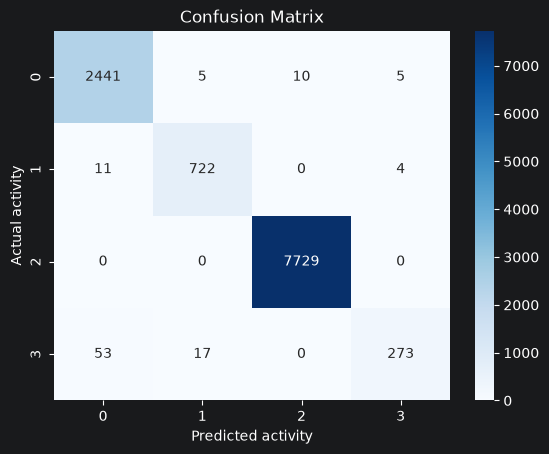

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted activity")
plt.ylabel("Actual activity")
plt.title("Confusion Matrix")
plt.show()

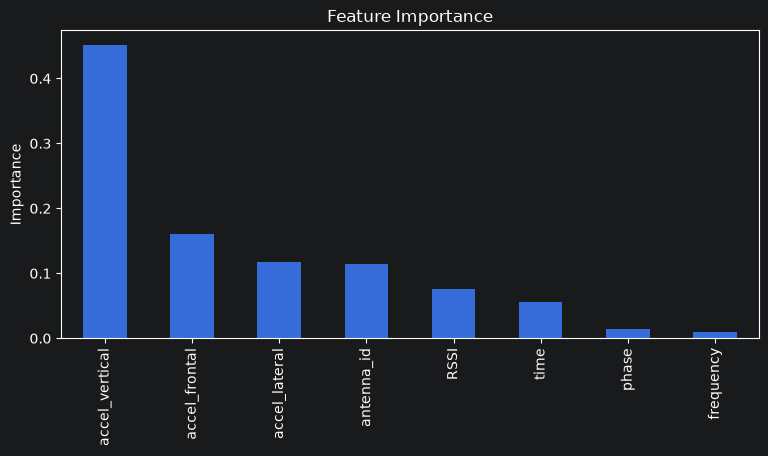

In [9]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.plot(kind="bar", figsize=(9, 4))
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()